In [57]:
import pandas as pd
import numpy as np
from tqdm import tqdm 
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats
import random
from scipy import stats
from scipy.stats import fisher_exact
from scipy.stats.contingency import expected_freq
import glob
sns.set(font_scale=1,style='ticks',rc={'grid.linestyle': '-','grid.linewidth': .5})
from uncertainties import ufloat
import scipy.optimize as opt 
from mycolorpy import colorlist as mcp


In [58]:
df = pd.read_excel("/Users/aelazar/Library/CloudStorage/OneDrive-SharedLibraries-St.JudeChildren'sResearchHospital/Trivedi, Vikas - Assaf-Vikas/IDR_dSAMs/TR-FRET/2023_10_18_APP_dAPP_dox_100_10_1_0.1.xlsx",sheet_name='Sheet1',
                  header=1)

df_488 = pd.read_excel("/Users/aelazar/Library/CloudStorage/OneDrive-SharedLibraries-St.JudeChildren'sResearchHospital/Trivedi, Vikas - Assaf-Vikas/IDR_dSAMs/TR-FRET/2023_10_18_APP_dAPP_dox_100_10_1_0.1.xlsx",sheet_name='Sheet2',
                  header=13)
dox = [100,10,1,0.1]
titration = []
for i,j in zip(dox,[2,3,4,5]):
    titration.append({'dox':i,'ele':'APP','surface_exp':df_488.loc[0:1,j].mean()})
for i,j in zip(dox,[2,3,4,5]):
    titration.append({'dox':i,'ele':'dAPP','surface_exp':df_488.loc[4:5,j].mean()})
titration_df= pd.DataFrame(titration)

In [59]:
row=['A','B','C']# APP,dAPP,control(?)
c_100= ['01','02','03']#100
c_10= ['04','05','06']#10
c_1= ['07','08','09']#1
c_zero_1 = ['10','11','12']#.1

In [60]:
l=[]
surf = titration_df[(titration_df.ele=='APP')&(titration_df.dox==100)].surface_exp.values[0]
for j in enumerate(c_100):
    c = 0
    vals = df[df['Unnamed: 0']=='A%s'%(c_100[j[0]])].iloc[:,2:].values[0]
    norm  = vals-vals[0]
    for val in norm:
        #print(val/surf)
        l.append({'dox':2,'ele':'APP','FRET':val,'time':c, 'rep':1,'FRET_norm_surface':val/surf})
        c = c +1
surf = titration_df[(titration_df.ele=='APP')&(titration_df.dox==10)].surface_exp.values[0]
for j in enumerate(c_10):
    c = 0
    vals = df[df['Unnamed: 0']=='A%s'%(c_10[j[0]])].iloc[:,2:].values[0]
    norm  = vals-vals[0]
    for val in norm:
        #print(val/surf)
        l.append({'dox':1,'ele':'APP','FRET':val,'time':c, 'rep':1,'FRET_norm_surface':val/surf})
        c = c +1
surf = titration_df[(titration_df.ele=='APP')&(titration_df.dox==1)].surface_exp.values[0]
for j in enumerate(c_10):
    c = 0
    vals = df[df['Unnamed: 0']=='A%s'%(c_1[j[0]])].iloc[:,2:].values[0]
    norm  = vals-vals[0]
    for val in norm:
        #print(val/surf)
        l.append({'dox':0,'ele':'APP','FRET':val,'time':c, 'rep':1,'FRET_norm_surface':val/surf})
        c = c +1
surf = titration_df[(titration_df.ele=='APP')&(titration_df.dox==.1)].surface_exp.values[0]
for j in enumerate(c_10):
    c = 0
    vals = df[df['Unnamed: 0']=='A%s'%(c_zero_1[j[0]])].iloc[:,2:].values[0]
    norm  = vals-vals[0]
    for val in norm:
        #print(val/surf)
        l.append({'dox':-1,'ele':'APP','FRET':val,'time':c, 'rep':1,'FRET_norm_surface':val/surf})
        c = c +1



surf = titration_df[(titration_df.ele=='dAPP')&(titration_df.dox==100)].surface_exp.values[0]
for j in enumerate(c_100):
    c = 0
    vals = df[df['Unnamed: 0']=='B%s'%(c_100[j[0]])].iloc[:,2:].values[0]
    norm  = vals-vals[0]
    for val in norm:
        #print(val/surf)
        l.append({'dox':2,'ele':'dAPP','FRET':val,'time':c, 'rep':1,'FRET_norm_surface':val/surf})
        c = c +1
surf = titration_df[(titration_df.ele=='dAPP')&(titration_df.dox==10)].surface_exp.values[0]
for j in enumerate(c_10):
    c = 0
    vals = df[df['Unnamed: 0']=='B%s'%(c_10[j[0]])].iloc[:,2:].values[0]
    norm  = vals-vals[0]
    for val in norm:
        #print(val/surf)
        l.append({'dox':1,'ele':'dAPP','FRET':val,'time':c, 'rep':1,'FRET_norm_surface':val/surf})
        c = c +1
surf = titration_df[(titration_df.ele=='dAPP')&(titration_df.dox==1)].surface_exp.values[0]
for j in enumerate(c_10):
    c = 0
    vals = df[df['Unnamed: 0']=='B%s'%(c_1[j[0]])].iloc[:,2:].values[0]
    norm  = vals-vals[0]
    for val in norm:
        #print(val/surf)
        l.append({'dox':0,'ele':'dAPP','FRET':val,'time':c, 'rep':1,'FRET_norm_surface':val/surf})
        c = c +1
surf = titration_df[(titration_df.ele=='dAPP')&(titration_df.dox==.1)].surface_exp.values[0]
for j in enumerate(c_10):
    c = 0
    vals = df[df['Unnamed: 0']=='B%s'%(c_zero_1[j[0]])].iloc[:,2:].values[0]
    norm  = vals-vals[0]
    for val in norm:
        #print(val/surf)
        l.append({'dox':-1,'ele':'dAPP','FRET':val,'time':c, 'rep':1,'FRET_norm_surface':val/surf})
        c = c +1














df = pd.read_excel("/Users/aelazar/Library/CloudStorage/OneDrive-SharedLibraries-St.JudeChildren'sResearchHospital/Trivedi, Vikas - Assaf-Vikas/IDR_dSAMs/TR-FRET/2023_10_23_APP_dAPP_dox_100_10_1_0.1.xlsx",sheet_name='Sheet1',
                  header=1)
df_488 = pd.read_excel("/Users/aelazar/Library/CloudStorage/OneDrive-SharedLibraries-St.JudeChildren'sResearchHospital/Trivedi, Vikas - Assaf-Vikas/IDR_dSAMs/TR-FRET/2023_10_23_APP_dAPP_dox_100_10_1_0.1.xlsx",sheet_name='Sheet2',
                  header=13)
dox = [100,10,1,0.1]
titration = []
for i,j in zip(dox,[2,3,4,5]):
    titration.append({'dox':i,'ele':'APP','surface_exp':df_488.loc[0:1,j].mean()})
for i,j in zip(dox,[2,3,4,5]):
    titration.append({'dox':i,'ele':'dAPP','surface_exp':df_488.loc[4:5,j].mean()})
titration_df= pd.DataFrame(titration)
row=['A','B','C']
c_100= ['01','02','03']#100
c_10= ['04','05','06']#10
c_1= ['07','08','09']#1
c_zero_1 = ['10','11','12']#.1

surf = titration_df[(titration_df.ele=='APP')&(titration_df.dox==100)].surface_exp.values[0]
for j in enumerate(c_100):
    c = 0
    vals = df[df['Unnamed: 0']=='A%s'%(c_100[j[0]])].iloc[:,2:].values[0]
    norm  = vals-vals[0]
    for val in norm:
        #print(val/surf)
        l.append({'dox':2,'ele':'APP','FRET':val,'time':c, 'rep':2,'FRET_norm_surface':val/surf})
        c = c +1
surf = titration_df[(titration_df.ele=='APP')&(titration_df.dox==10)].surface_exp.values[0]
for j in enumerate(c_10):
    c = 0
    vals = df[df['Unnamed: 0']=='A%s'%(c_10[j[0]])].iloc[:,2:].values[0]
    norm  = vals-vals[0]
    for val in norm:
        #print(val/surf)
        l.append({'dox':1,'ele':'APP','FRET':val,'time':c, 'rep':2,'FRET_norm_surface':val/surf})
        c = c +1
surf = titration_df[(titration_df.ele=='APP')&(titration_df.dox==1)].surface_exp.values[0]
for j in enumerate(c_10):
    c = 0
    vals = df[df['Unnamed: 0']=='A%s'%(c_1[j[0]])].iloc[:,2:].values[0]
    norm  = vals-vals[0]
    for val in norm:
        #print(val/surf)
        l.append({'dox':0,'ele':'APP','FRET':val,'time':c, 'rep':2,'FRET_norm_surface':val/surf})
        c = c +1
surf = titration_df[(titration_df.ele=='APP')&(titration_df.dox==.1)].surface_exp.values[0]
for j in enumerate(c_10):
    c = 0
    vals = df[df['Unnamed: 0']=='A%s'%(c_zero_1[j[0]])].iloc[:,2:].values[0]
    norm  = vals-vals[0]
    for val in norm:
        #print(val/surf)
        l.append({'dox':-1,'ele':'APP','FRET':val,'time':c, 'rep':2,'FRET_norm_surface':val/surf})
        c = c +1



surf = titration_df[(titration_df.ele=='dAPP')&(titration_df.dox==100)].surface_exp.values[0]
for j in enumerate(c_100):
    c = 0
    vals = df[df['Unnamed: 0']=='B%s'%(c_100[j[0]])].iloc[:,2:].values[0]
    norm  = vals-vals[0]
    for val in norm:
        #print(val/surf)
        l.append({'dox':2,'ele':'dAPP','FRET':val,'time':c, 'rep':2,'FRET_norm_surface':val/surf})
        c = c +1
surf = titration_df[(titration_df.ele=='dAPP')&(titration_df.dox==10)].surface_exp.values[0]
for j in enumerate(c_10):
    c = 0
    vals = df[df['Unnamed: 0']=='B%s'%(c_10[j[0]])].iloc[:,2:].values[0]
    norm  = vals-vals[0]
    for val in norm:
        #print(val/surf)
        l.append({'dox':1,'ele':'dAPP','FRET':val,'time':c, 'rep':2,'FRET_norm_surface':val/surf})
        c = c +1
surf = titration_df[(titration_df.ele=='dAPP')&(titration_df.dox==1)].surface_exp.values[0]
for j in enumerate(c_10):
    c = 0
    vals = df[df['Unnamed: 0']=='B%s'%(c_1[j[0]])].iloc[:,2:].values[0]
    norm  = vals-vals[0]
    for val in norm:
        #print(val/surf)
        l.append({'dox':0,'ele':'dAPP','FRET':val,'time':c, 'rep':2,'FRET_norm_surface':val/surf})
        c = c +1
surf = titration_df[(titration_df.ele=='dAPP')&(titration_df.dox==.1)].surface_exp.values[0]
for j in enumerate(c_10):
    c = 0
    vals = df[df['Unnamed: 0']=='B%s'%(c_zero_1[j[0]])].iloc[:,2:].values[0]
    norm  = vals-vals[0]
    for val in norm:
        #print(val/surf)
        l.append({'dox':-1,'ele':'dAPP','FRET':val,'time':c, 'rep':2,'FRET_norm_surface':val/surf})
        c = c +1



In [61]:
df = pd.read_excel("/Users/aelazar/Library/CloudStorage/OneDrive-SharedLibraries-St.JudeChildren'sResearchHospital/Trivedi, Vikas - Assaf-Vikas/IDR_dSAMs/TR-FRET/2025_05_12_APP_dAPP_dox_100_10_1_0.1_R3.xlsx",sheet_name='Table All Cycles',
                  header=10)
# df_488 = pd.read_excel("/Users/aelazar/Library/CloudStorage/OneDrive-SharedLibraries-St.JudeChildren'sResearchHospital/Trivedi, Vikas - Assaf-Vikas/IDR_dSAMs/TR-FRET/2023_10_23_APP_dAPP_dox_100_10_1_0.1.xlsx",sheet_name='Sheet2',
#                   header=13)

<Axes: xlabel='Unnamed: 1'>

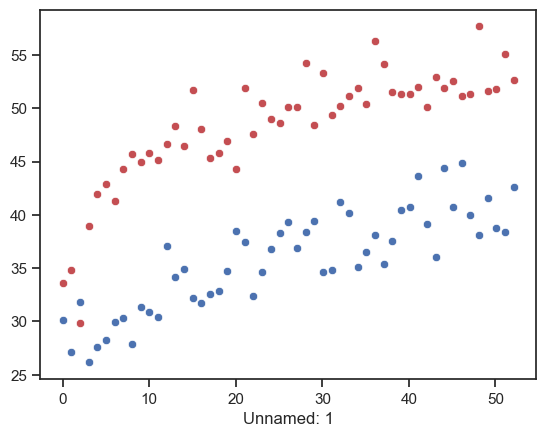

In [62]:
sns.scatterplot(x=df.iloc[1:54:,1],y=[i/469 for i in df.iloc[1:54:,8]],color='r')
sns.scatterplot(x=df.iloc[1:54:,1],y=[i/542 for i in df.iloc[1:54:,22]])

In [63]:
ll = pd.DataFrame(l)
df  = ll.groupby(['time','ele','dox','rep']).mean().reset_index()
df = df[df.time.between(50,600)]
df['FRET_norm_surface']*1000

800     1.205083
801     0.222550
802     0.747768
803     0.008095
804    -0.046330
          ...   
9603    2.724835
9604    0.180129
9605    0.218155
9606    0.254015
9607    0.328161
Name: FRET_norm_surface, Length: 8808, dtype: float64

In [64]:
df

,time,ele,dox,rep,FRET,FRET_norm_surface
800,50,APP,-1,1,0.121713,0.001205
801,50,APP,-1,2,0.020363,0.000223
802,50,APP,0,1,0.088237,0.000748
803,50,APP,0,2,0.000793,0.000008
804,50,APP,1,1,-0.005050,-0.000046
...,...,...,...,...,...,...
9603,600,APP,2,2,0.317443,0.002725
9604,600,dAPP,-1,2,0.070070,0.000180
9605,600,dAPP,0,2,0.131220,0.000218
9606,600,dAPP,1,2,0.178953,0.000254


In [65]:
df['time'] =df['time']-50
df['FRET_norm_surface']= df['FRET_norm_surface']*1000

In [66]:
df[(df.ele=='APP')&(df.dox==-1)&(df.time==1)]

,time,ele,dox,rep,FRET,FRET_norm_surface
816,1,APP,-1,1,0.087680,0.868119
817,1,APP,-1,2,0.036087,0.394390


<Axes: xlabel='time', ylabel='FRET_norm_surface'>

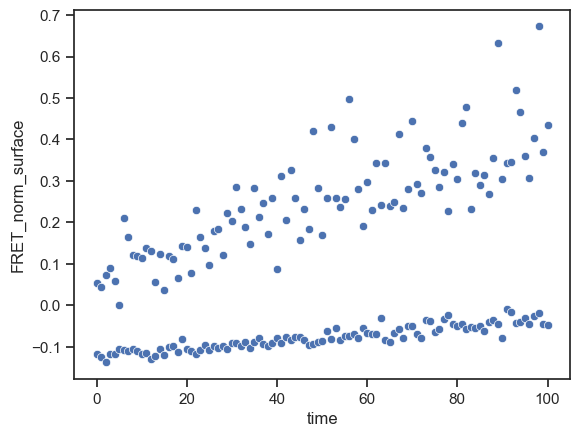

In [67]:
sns.scatterplot(x='time',y='FRET_norm_surface',data=df[(df.ele=='dAPP')&(df.dox==-1)&(df.time.between(0,100))])

(0.0, 3.0)

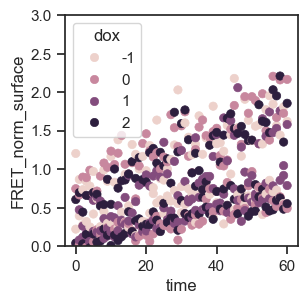

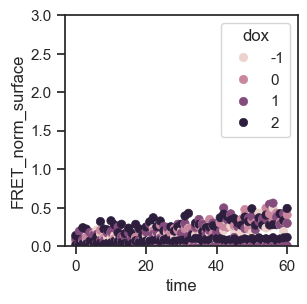

In [68]:
fig, ax = plt.subplots(figsize=(3,3)) 
sns.scatterplot(x='time',y='FRET_norm_surface',data=df[(df.ele=='APP')&(df.time.between(0,60))],hue='dox',edgecolor=None)
plt.ylim([0,3])
fig, ax = plt.subplots(figsize=(3,3)) 
sns.scatterplot(x='time',y='FRET_norm_surface',data=df[(df.ele=='dAPP')&(df.time.between(0,60))],hue='dox',edgecolor=None)
plt.ylim([0,3])

(0.0, 590.0)

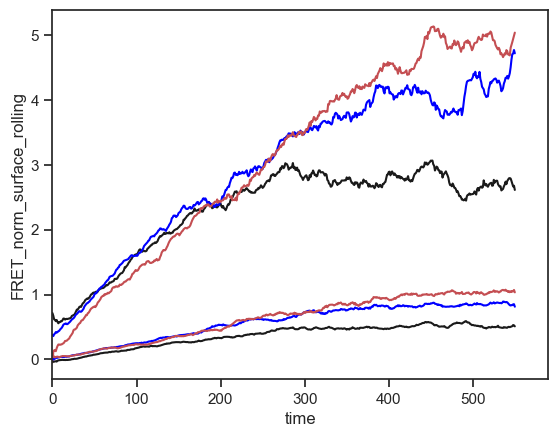

In [69]:
color = ['k','blue','r','orange']
c = 0
for dox in [-1,0,1]:
    
    t = df[(df.ele=='APP')&(df.dox==dox)].loc[:,['time','FRET_norm_surface']].groupby(['time']).mean().reset_index()
    t['FRET_norm_surface_rolling'] = t['FRET_norm_surface'].rolling(window=21,min_periods=1).mean()
    sns.lineplot(x='time',y='FRET_norm_surface_rolling',data=t,c=color[c])
    c = c+1
c = 0
for dox in [-1,0,1]:
    
    t = df[(df.ele=='dAPP')&(df.dox==dox)].loc[:,['time','FRET_norm_surface']].groupby(['time']).mean().reset_index()
    t['FRET_norm_surface_rolling'] = t['FRET_norm_surface'].rolling(window=21,min_periods=1).mean()
    sns.lineplot(x='time',y='FRET_norm_surface_rolling',data=t,c=color[c])
    c = c+1
#plt.yscale('log')
plt.xlim([0,590])

In [70]:
def tau_function_v2(t,A,tau):#y(t)=A⋅(1−e−τ⋅t)
    '''fitting recovery 
     - I_zero: Bottom
     - a: 
     - b: beta '''
    return A*(1-np.exp(-tau*t))
def linearReg(x,a,b):
    '''fitting recovery 
     - I_zero: Bottom
     - a: 
     - b: beta '''
    return a*x  + b

def prisim(t,Y0,Plateau,K):
    '''fitting recovery 
     - I_zero: Bottom
     - a: 
     - b: beta '''
    return Y0 + (Plateau-Y0)*(1-np.exp(-K*t))

In [72]:
from sklearn.metrics import r2_score
def opt2df(ele='APP',dox=-1):
    t = df[(df.ele==ele)&(df.dox==dox)].loc[:,['time','FRET_norm_surface']].groupby(['time']).mean()
    t['FRET_norm_surface_rolling'] = t['FRET_norm_surface'].rolling(window=10,min_periods=1).mean()
    x = t.groupby(['time']).mean().index.values[1:]
    y =t.groupby(['time']).mean().FRET_norm_surface_rolling.values[1:]
    tt = df[(df.ele==ele)&(df.dox==dox)].loc[:,['time','FRET_norm_surface']].groupby(['time']).sem().reset_index()
    tt['FRET_norm_surface_rolling'] = tt['FRET_norm_surface'].rolling(window=10,min_periods=1).mean()
    stds = tt.FRET_norm_surface_rolling.values[1:]
    fit, covar = opt.curve_fit(tau_function_v2, x, y,sigma=stds,
                               
                               absolute_sigma = True,maxfev=10000)
    sigma_ab = np.sqrt(np.diagonal(covar))
    y_pred = tau_function_v2(x, *fit)
    #print(r2_score(y, y_pred))
    slope = ufloat(fit[0], sigma_ab[0])
    b = ufloat(fit[1], sigma_ab[1])
    text_res = "Best fit parameters:\na = {}\nb = {}".format(slope, b)
    #print(text_res)
    #print(fit)
    
    return pd.DataFrame({'x':x,'y':y,'y_pred':y_pred,'stds':stds,'dox':dox,'ele':ele}),pd.DataFrame([{'ele':ele,'dox':dox,'A':fit[0],'tau':fit[1],'half':np.log(.5)/-1*(fit[1]),'err_A':sigma_ab[0],'err_tau':sigma_ab[1],'r2':r2_score(y, y_pred)}])
    #fit[0],fit[1],sigma_ab[0],sigma_ab[1]#pd.DataFrame([x,y,stds])

In [73]:
plot_df = pd.DataFrame()
fit_df = pd.DataFrame()
for e in ['APP','dAPP']:
    for i in [-1,0,1]: 
        p,t = opt2df(ele=e,dox=i)
    
        plot_df= pd.concat([plot_df,p],ignore_index=True)
        fit_df  = pd.concat([fit_df,t],ignore_index=True)

/var/folders/5x/p2xckt5d54zdnw2nd23zc4lm0000gp/T/ipykernel_4643/459636233.py:6: RuntimeWarning: overflow encountered in exp
  return A*(1-np.exp(-tau*t))
/var/folders/5x/p2xckt5d54zdnw2nd23zc4lm0000gp/T/ipykernel_4643/459636233.py:6: RuntimeWarning: overflow encountered in exp
  return A*(1-np.exp(-tau*t))
/var/folders/5x/p2xckt5d54zdnw2nd23zc4lm0000gp/T/ipykernel_4643/459636233.py:6: RuntimeWarning: overflow encountered in exp
  return A*(1-np.exp(-tau*t))


In [74]:
plot_df

,x,y,y_pred,stds,dox,ele
0,1,0.672535,0.028420,0.364065,-1,APP
1,2,0.617066,0.056545,0.318875,-1,APP
2,3,0.608313,0.084379,0.304352,-1,APP
3,4,0.589820,0.111924,0.296457,-1,APP
4,5,0.607321,0.139184,0.293064,-1,APP
...,...,...,...,...,...,...
3295,546,1.023777,1.158653,0.829883,1,dAPP
3296,547,1.055710,1.160269,0.859953,1,dAPP
3297,548,1.046754,1.161884,0.846645,1,dAPP
3298,549,1.040310,1.163496,0.836488,1,dAPP


0.6362165897295045
0.9667327122443286
Best fit parameters:
a = 2.04+/-0.16
b = 4.77+/-0.15
Best fit parameters:
a = 0.61+/-0.22
b = 1.27+/-0.20


/var/folders/5x/p2xckt5d54zdnw2nd23zc4lm0000gp/T/ipykernel_4643/2623367114.py:76: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i].set_xticklabels(axs[i].get_xticklabels(),fontsize=24,rotation=0)
/var/folders/5x/p2xckt5d54zdnw2nd23zc4lm0000gp/T/ipykernel_4643/2623367114.py:77: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i].set_yticklabels(axs[i].get_yticklabels(),fontsize=24,rotation=0)
/var/folders/5x/p2xckt5d54zdnw2nd23zc4lm0000gp/T/ipykernel_4643/2623367114.py:76: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i].set_xticklabels(axs[i].get_xticklabels(),fontsize=24,rotation=0)
/var/folders/5x/p2xckt5d54zdnw2nd23zc4lm0000gp/T/ipykernel_4643/2623367114.py:77: UserWarning: set_ticklabels() should only be used with a fixed num

Text(0, 0.5, '')

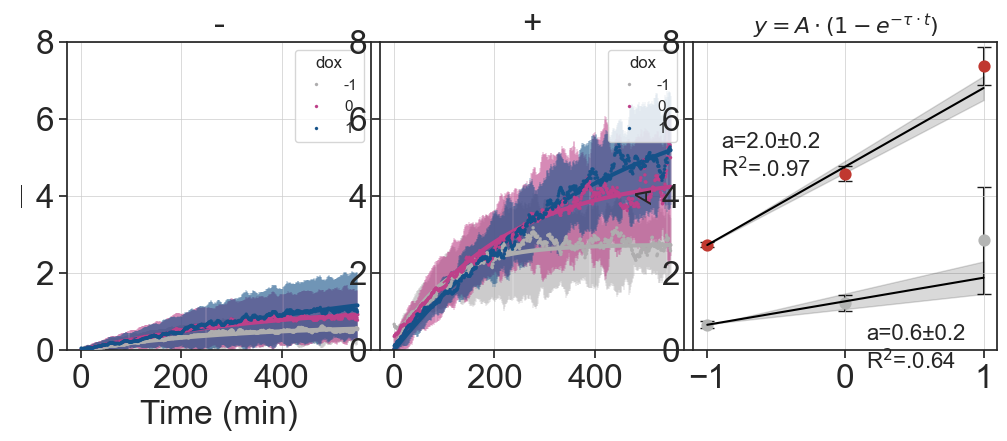

In [75]:
fig = plt.figure(figsize = ((12),4))#20,10
sns.set(font_scale=1,style='ticks',rc={'grid.linestyle': '-','grid.linewidth': .5})
axs = fig.subplots(nrows=1, ncols=3,gridspec_kw = {'hspace':.05,'wspace':.03})
color = ['#AEADAE','#BD4089','#155289']#mcp.gen_color(cmap="Blues",n=3)#['blue','r','orange']
#fig, ax = plt.subplots(figsize=(5,5)) 
for i in enumerate([-1,0,1]):
    x = plot_df[(plot_df.ele=='dAPP')&(plot_df.dox==i[1])].x
    y = plot_df[(plot_df.ele=='dAPP')&(plot_df.dox==i[1])].y_pred
    err = plot_df[(plot_df.ele=='dAPP')&(plot_df.dox==i[1])].stds
    axs[0].errorbar(x,y,yerr=err,capsize=0,elinewidth=.3,ecolor=color[i[0]],color=color[i[0]],linewidth=3)
sns.scatterplot(x='x',y='y',data=plot_df[plot_df.ele=='dAPP'],hue='dox',palette=color,s=5,edgecolor=None,ax=axs[0],zorder=4)


axs[0].grid()
for i in enumerate([-1,0,1]):
    x = plot_df[(plot_df.ele=='APP')&(plot_df.dox==i[1])].x
    y = plot_df[(plot_df.ele=='APP')&(plot_df.dox==i[1])].y_pred
    err = plot_df[(plot_df.ele=='APP')&(plot_df.dox==i[1])].stds
    axs[1].errorbar(x,y,yerr=err,capsize=0,elinewidth=.3,ecolor=color[i[0]],color=color[i[0]],linewidth=3)
sns.scatterplot(x='x',y='y',data=plot_df[plot_df.ele=='APP'],hue='dox',palette=color,s=5,edgecolor=None,ax=axs[1],zorder=4)
axs[0].set_ylim([0,8])
axs[1].set_ylim([0,8])
axs[2].set_ylim([0,8])
axs[2].locator_params(nbins=4)
axs[1].locator_params(nbins=4)
axs[0].locator_params(nbins=4)
axs[1].grid()
#axs[1].set_yticklabels([])

## Platue fiiting regersion 

sns.pointplot(x='dox',y='A',hue='ele',data=fit_df,native_scale=True,linestyles='none',ax=axs[2],hue_order=['dAPP','APP'],palette=['#B4B5B4','#C03830'])
#sns.pointplot(x='dox', y='err', data=reg_df, color='red', markers='x', linestyles='None')  # Plot error values separately
axs[2].errorbar(x=fit_df[fit_df.ele=='dAPP']['dox'], y=fit_df[fit_df.ele=='dAPP']['A'], yerr=fit_df[fit_df.ele=='dAPP']['err_A'], 
                fmt='none', capsize=5, capthick=1, color='k',zorder=0,rasterized=True)
axs[2].errorbar(x=fit_df[fit_df.ele=='APP']['dox'], y=fit_df[fit_df.ele=='APP']['A'], yerr=fit_df[fit_df.ele=='APP']['err_A'],
                fmt='none', capsize=5, capthick=1, color='k',zorder=0,rasterized=True)

#https://stackoverflow.com/questions/39434402/how-to-get-confidence-intervals-from-curve-fit
#dAPP
y_dAPP= fit_df[fit_df.ele=='dAPP']['A'].values
y_dAP_err = fit_df[fit_df.ele=='dAPP']['err_A'].values
x = np.array([-1,0,1])
fit_dAPP, covar_dAPP = opt.curve_fit(linearReg,x, y_dAPP,
                           sigma = y_dAP_err,
                           absolute_sigma = True,maxfev=10000)
sigma_ab_dAPP = np.sqrt(np.diagonal(covar_dAPP))
y_pred_dAPP = linearReg(x, *fit_dAPP)
print(r2_score(y_dAPP, y_pred_dAPP))
plt.plot([-1,0,1], linearReg(x, *fit_dAPP), 'black')
bound_upper_dAPP = linearReg(x, *(fit_dAPP + sigma_ab_dAPP))
bound_lower_dAPP = linearReg(x, *(fit_dAPP - sigma_ab_dAPP))
# plotting the confidence intervals
axs[2].fill_between(x, bound_lower_dAPP, bound_upper_dAPP,
                 color = 'black', alpha = 0.15)
#APP
y_APP= fit_df[fit_df.ele=='APP']['A'].values
y_APP_err = fit_df[fit_df.ele=='APP']['err_A'].values
x = np.array([-1,0,1])
fit_APP, covar_APP = opt.curve_fit(linearReg,x, y_APP,
                           sigma = y_APP_err,
                           absolute_sigma = True,maxfev=10000)
sigma_ab_APP = np.sqrt(np.diagonal(covar_APP))
y_pred_APP = linearReg(x, *fit_APP)
print(r2_score(y_APP, y_pred_APP))
axs[2].plot([-1,0,1], linearReg(x, *fit_APP), 'black')
bound_upper_APP = linearReg(x, *(fit_APP + sigma_ab_APP))
bound_lower_APP = linearReg(x, *(fit_APP - sigma_ab_APP))
# plotting the confidence intervals
axs[2].fill_between(x, bound_lower_APP, bound_upper_APP,
                 color = 'black', alpha = 0.15)
axs[2].grid()
# axs[2].locator_params(nbins=2)
axs[0].locator_params(nbins=4)
for i in [0,1,2]:
    axs[i].set_xticklabels(axs[i].get_xticklabels(),fontsize=24,rotation=0)
    axs[i].set_yticklabels(axs[i].get_yticklabels(),fontsize=24,rotation=0)
#axs[2].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
axs[1].set_xticklabels(axs[1].get_xticklabels(),fontsize=16,rotation=0)
axs[0].set_ylabel('$\\frac{\;\;\;\;\;}{\;\;\;\;\;}$',fontsize=16)#[490]520]otal expression
axs[0].set_xlabel('Time (min)',fontsize=24)
axs[2].set_title('$y=A\\cdot (1-e^{-\\tau \\cdot t})$',fontsize=16)
axs[1].set_title('+',fontsize=24)
axs[0].set_title('-',fontsize=24)

slope = ufloat(fit_APP[0], sigma_ab_APP[0])
b = ufloat(fit_APP[1], sigma_ab_APP[1])
text_res = "Best fit parameters:\na = {}\nb = {}".format(slope, b)
print(text_res)
slope = ufloat(fit_dAPP[0], sigma_ab_dAPP[0])
b = ufloat(fit_dAPP[1], sigma_ab_dAPP[1])
#axs[2].set_ylim([-1,9])

axs[2].legend([],frameon=False,)#ncol=2,loc='upper center',fontsize=16)
#axs[1].legend(ncol=2,loc='upper center',fontsize=16)
axs[2].set_ylabel('$A$',fontsize=16)
# ax.locator_params(axis='x',nbins=3)
# ax.locator_params(axis='y',nbins=4)
text_res = "Best fit parameters:\na = {}\nb = {}".format(slope, b)
print(text_res)
axs[2].text(-.9,4.5,"a=%.1f±%.1f\nR$^{2}$=.%.2f"%(fit_APP[0],sigma_ab_APP[0],r2_score(y_APP, y_pred_APP)),fontsize=16)
axs[2].text(.15,-.50,"a=%.1f±%.1f\nR$^{2}$=.%.2f"%(fit_dAPP[0],sigma_ab_dAPP[0],r2_score(y_dAPP, y_pred_dAPP)),fontsize=16)
#plt.suptitle('mdSAM',y=1.05,x=.35,fontsize=16)
axs[2].set_xticklabels(axs[2].get_xticklabels(),fontsize=24,rotation=0)
axs[1].set_xticklabels(axs[1].get_xticklabels(),fontsize=24,rotation=0)
axs[2].set_xlabel('',fontsize=16)
axs[1].set_xlabel('',fontsize=24)
axs[1].set_ylabel('',fontsize=24)
#plt.savefig('TR-FRET_dox_v2.svg',bbox_inches='tight',transparent=True)

-3.7821717537778055
0.9667327122443286


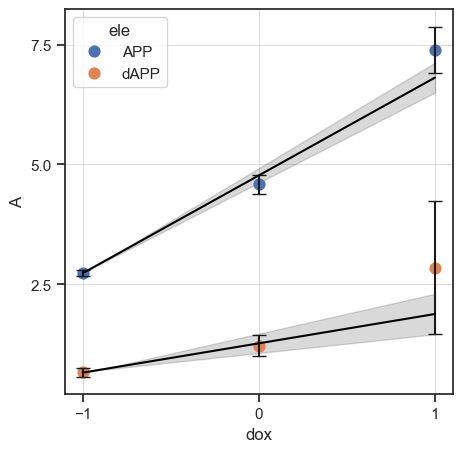

In [76]:
fig, ax = plt.subplots(figsize=(5,5)) 
sns.pointplot(x='dox',y='A',hue='ele',data=fit_df,native_scale=True,linestyles='none',)
#sns.pointplot(x='dox', y='err', data=reg_df, color='red', markers='x', linestyles='None')  # Plot error values separately
plt.errorbar(x=fit_df[fit_df.ele=='dAPP']['dox'], y=fit_df[fit_df.ele=='dAPP']['A'], yerr=fit_df[fit_df.ele=='dAPP']['err_A'], fmt='none', capsize=5, capthick=1, color='k')
plt.errorbar(x=fit_df[fit_df.ele=='APP']['dox'], y=fit_df[fit_df.ele=='APP']['A'], yerr=fit_df[fit_df.ele=='APP']['err_A'], fmt='none', capsize=5, capthick=1, color='k')

#https://stackoverflow.com/questions/39434402/how-to-get-confidence-intervals-from-curve-fit
#dAPP
y_dAPP= fit_df[fit_df.ele=='dAPP']['A'].values
y_dAP_err = fit_df[fit_df.ele=='dAPP']['err_A'].values
x = np.array([-1,0,1])
fit_dAPP, covar_dAPP = opt.curve_fit(linearReg,x, y_dAPP,
                           sigma = y_dAP_err,
                           absolute_sigma = True,maxfev=10000)
sigma_ab_dAPP = np.sqrt(np.diagonal(covar_dAPP))
y_pred_dAPP = tau_function_v2(x, *fit_dAPP)
print(r2_score(y_dAPP, y_pred_dAPP))
plt.plot([-1,0,1], linearReg(x, *fit_dAPP), 'black')
bound_upper_dAPP = linearReg(x, *(fit_dAPP + sigma_ab_dAPP))
bound_lower_dAPP = linearReg(x, *(fit_dAPP - sigma_ab_dAPP))
# plotting the confidence intervals
plt.fill_between(x, bound_lower_dAPP, bound_upper_dAPP,
                 color = 'black', alpha = 0.15)
#APP
y_APP= fit_df[fit_df.ele=='APP']['A'].values
y_APP_err = fit_df[fit_df.ele=='APP']['err_A'].values
x = np.array([-1,0,1])
fit_APP, covar_APP = opt.curve_fit(linearReg,x, y_APP,
                           sigma = y_APP_err,
                           absolute_sigma = 1,maxfev=10000)
sigma_ab_APP = np.sqrt(np.diagonal(covar_APP))
y_pred_APP = linearReg(x, *fit_APP)
print(r2_score(y_APP, y_pred_APP))
plt.plot([-1,0,1], linearReg(x, *fit_APP), 'black')
bound_upper_APP = linearReg(x, *(fit_APP + sigma_ab_APP))
bound_lower_APP = linearReg(x, *(fit_APP - sigma_ab_APP))
# plotting the confidence intervals
plt.fill_between(x, bound_lower_APP, bound_upper_APP,
                 color = 'black', alpha = 0.15)
ax.grid()
plt.locator_params(nbins=3)

In [77]:
plot_df.x.max()

550

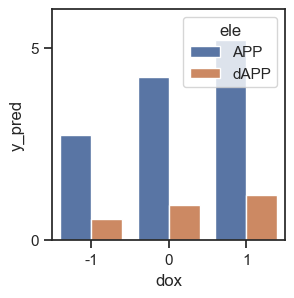

In [78]:
fig, ax = plt.subplots(figsize=(3,3))
sns.barplot(x='dox',y='y_pred',data=plot_df[(plot_df.x==550)],hue='ele')
plt.ylim([0,6])
plt.locator_params(axis='y',nbins=2)

In [81]:
agg_data = df[(df.time.between(300,550))&(df.dox!=2)].groupby(['rep','ele','dox']).mean().reset_index()

In [82]:
a  = agg_data[(agg_data.dox==-1)&(agg_data.ele=='dAPP')&(agg_data.rep==1)].FRET_norm_surface.values[0]
b  = agg_data[(agg_data.dox==-1)&(agg_data.ele=='APP')&(agg_data.rep==1)].FRET_norm_surface.values[0]
aa = agg_data[(agg_data.dox==-1)&(agg_data.ele=='dAPP')&(agg_data.rep==2)].FRET_norm_surface.values[0]
bb  = agg_data[(agg_data.dox==-1)&(agg_data.ele=='APP')&(agg_data.rep==2)].FRET_norm_surface.values[0]

c  = agg_data[(agg_data.dox==0)&(agg_data.ele=='dAPP')&(agg_data.rep==1)].FRET_norm_surface.values[0]
d  = agg_data[(agg_data.dox==0)&(agg_data.ele=='APP')&(agg_data.rep==1)].FRET_norm_surface.values[0]
cc = agg_data[(agg_data.dox==0)&(agg_data.ele=='dAPP')&(agg_data.rep==2)].FRET_norm_surface.values[0]
dd  = agg_data[(agg_data.dox==0)&(agg_data.ele=='APP')&(agg_data.rep==2)].FRET_norm_surface.values[0]

e  = agg_data[(agg_data.dox==1)&(agg_data.ele=='dAPP')&(agg_data.rep==1)].FRET_norm_surface.values[0]
f  = agg_data[(agg_data.dox==1)&(agg_data.ele=='APP')&(agg_data.rep==1)].FRET_norm_surface.values[0]
ee = agg_data[(agg_data.dox==1)&(agg_data.ele=='dAPP')&(agg_data.rep==2)].FRET_norm_surface.values[0]
ff  = agg_data[(agg_data.dox==1)&(agg_data.ele=='APP')&(agg_data.rep==2)].FRET_norm_surface.values[0]


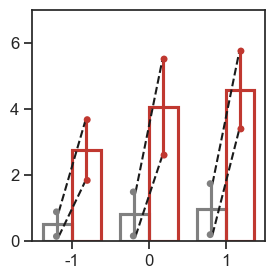

In [83]:
fig, ax = plt.subplots(figsize=(3,3))
sns.barplot(x='dox',y='FRET_norm_surface',data = agg_data,hue='ele',errorbar='se',fill=False,
            palette=['gray','#C03830'],hue_order=['dAPP','APP'],width=.75)
sns.stripplot(x='dox',y='FRET_norm_surface',data = agg_data,hue='ele',palette=['gray','#C03830'],hue_order=['dAPP','APP'],dodge=True,jitter=False)
plt.legend([],frameon=False)
plt.ylim([0,7])
plt.locator_params(axis='y',nbins=4)
plt.yticks(fontsize=12)
plt.xticks(fontsize=12)
plt.ylabel('')
plt.xlabel('')

plt.plot([-.17,.18],[a,b],ls='--',color='k')
plt.plot([-.17,.18],[aa,bb],ls='--',color='k')
plt.plot([1-.17,1+.18],[c,d],ls='--',color='k')
plt.plot([1-.17,1+.18],[cc,dd],ls='--',color='k')
plt.plot([2-.17,2+.18],[e,f],ls='--',color='k')
plt.plot([2-.17,2+.18],[ee,ff],ls='--',color='k')
plt.savefig('TR-FRET_dox_dAPP_v5.svg',bbox_inches='tight',transparent=True)

In [84]:
stats.ttest_rel(agg_data[(agg_data.dox==-1)&(agg_data.ele=='dAPP')]['FRET_norm_surface'],
agg_data[(agg_data.dox==-1)&(agg_data.ele=='APP')]['FRET_norm_surface'],alternative='less')

TtestResult(statistic=-4.097339451835872, pvalue=0.07619736324315146, df=1)

<Axes: xlabel='time', ylabel='FRET_norm_surface'>

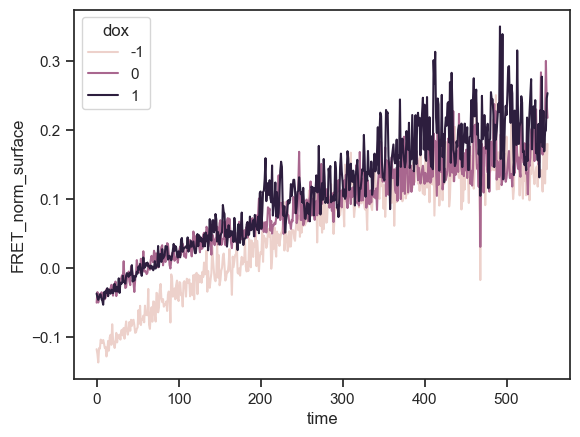

In [85]:
sns.lineplot(x='time',y='FRET_norm_surface',data=df[(df.rep==2)&(df.dox!=2)&(df.ele=='dAPP')],hue='dox')

In [86]:
df['time_h'] = df['time']/60

In [87]:
df

,time,ele,dox,rep,FRET,FRET_norm_surface,time_h
800,0,APP,-1,1,0.121713,1.205083,0.000000
801,0,APP,-1,2,0.020363,0.222550,0.000000
802,0,APP,0,1,0.088237,0.747768,0.000000
803,0,APP,0,2,0.000793,0.008095,0.000000
804,0,APP,1,1,-0.005050,-0.046330,0.000000
...,...,...,...,...,...,...,...
9603,550,APP,2,2,0.317443,2.724835,9.166667
9604,550,dAPP,-1,2,0.070070,0.180129,9.166667
9605,550,dAPP,0,2,0.131220,0.218155,9.166667
9606,550,dAPP,1,2,0.178953,0.254015,9.166667


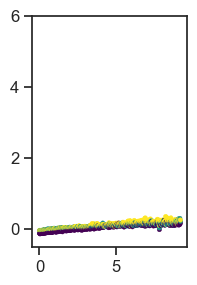

In [88]:
fig, ax = plt.subplots(figsize=(2,3))
sns.scatterplot(x='time_h',y='FRET_norm_surface',data=df[(df.rep==2)&(df.dox!=2)&(df.ele=='dAPP')],
                hue='dox',edgecolor=None,s=10,palette='viridis',alpha=1)
# sns.scatterplot(x='time_h',y='FRET_norm_surface',data=df[(df.rep==2)&(df.dox!=2)&(df.ele=='dAPP')],
#                 hue='dox',edgecolor=None,s=10,palette='viridis',alpha=1)

plt.ylim([-.5,6])
plt.locator_params(axis='both',nbins=4)
plt.yticks(fontsize=12)
plt.xticks(fontsize=12)
plt.ylabel('')
plt.xlabel('')
#plt.yscale('log')
plt.legend([],frameon=False)
plt.savefig('TR-FRET_dox_dAPP_v6.svg',bbox_inches='tight',transparent=True)

<Axes: xlabel='time_h', ylabel='FRET_norm_surface'>

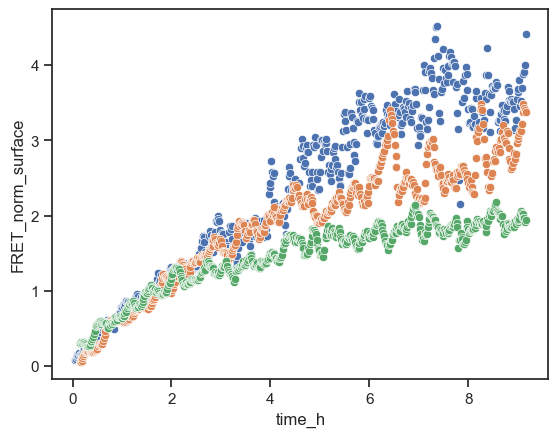

In [89]:
sns.scatterplot(x=df[(df.rep==2)&(df.dox==1)&(df.ele=='APP')]['time_h']
                ,y=df[(df.rep==2)&(df.dox==1)&(df.ele=='APP')]['FRET_norm_surface'].rolling(window=4).mean())
sns.scatterplot(x=df[(df.rep==2)&(df.dox==0)&(df.ele=='APP')]['time_h']
                ,y=df[(df.rep==2)&(df.dox==0)&(df.ele=='APP')]['FRET_norm_surface'].rolling(window=10).mean())
sns.scatterplot(x=df[(df.rep==2)&(df.dox==-1)&(df.ele=='APP')]['time_h']
                ,y=df[(df.rep==2)&(df.dox==-1)&(df.ele=='APP')]['FRET_norm_surface'].rolling(window=10).mean())

In [90]:
z = []
for t in range(0
               ,600,1):
    for j in [1,2]:
        for i in [-1,0,1]:
            t_1 = (df[(df.rep==j)&(df.dox==i)&(df.ele=='dAPP')&(df.time==t)].FRET_norm_surface.values[0])
            t_0 = (df[(df.rep==j)&(df.dox==i)&(df.ele=='dAPP')&(df.time==0)].FRET_norm_surface.values[0])
            z.append({'val':t_1-t_0,'dox':i,'rep':j,'ele':'dAPP','time':t})
        for i in [-1,0,1]:
            t_1 = (df[(df.rep==j)&(df.dox==i)&(df.ele=='APP')&(df.time==t)].FRET_norm_surface.values[0])
            t_0 = (df[(df.rep==j)&(df.dox==i)&(df.ele=='APP')&(df.time==0)].FRET_norm_surface.values[0])
            z.append({'val':t_1-t_0,'dox':i,'rep':j,'ele':'APP','time':t})


IndexError: index 0 is out of bounds for axis 0 with size 0

<Axes: xlabel='dox', ylabel='val'>

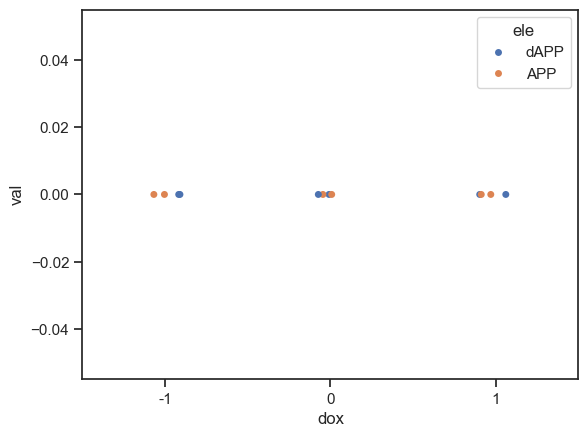

In [91]:
zz = pd.DataFrame(z)
#sns.stripplot(x='dox',y='val',data=zz[zz.time==30],hue='ele',dodge=True)
#sns.pointplot(x='dox',y='val',data=zz[zz.time==30],hue='ele',dodge=False,errorbar='se')
sns.stripplot(x='dox',y='val',data=zz[zz.time==0],hue='ele',dodge=False)

In [92]:
stats.ttest_ind(zz[(zz.time==60)&(zz.dox==1)&(zz.ele=='dAPP')].val,
zz[(zz.time==60)&(zz.dox==1)&(zz.ele=='APP')].val)

TtestResult(statistic=-2.7605638681486435, pvalue=0.10999146241649549, df=2.0)

<Axes: xlabel='time', ylabel='val'>

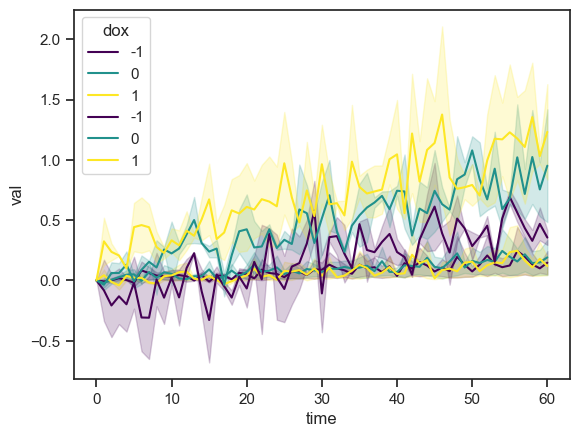

In [94]:
sns.lineplot(x='time',y='val',data=zz[(zz.ele=='dAPP')&(zz.time.between(0,60))],hue='dox',palette='viridis',alpha=1)
sns.lineplot(x='time',y='val',data=zz[(zz.ele=='APP')&(zz.time.between(0,60))],hue='dox',palette='viridis',alpha=1)

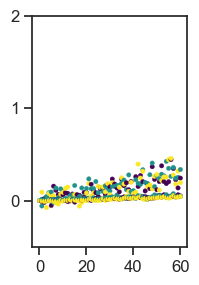

In [95]:
fig, ax = plt.subplots(figsize=(2,3))
sns.scatterplot(x='time',y='val',data=zz[(zz.ele=='dAPP')&(zz.time.between(0,60))],
                hue='dox',edgecolor=None,s=10,palette='viridis',alpha=1)
# sns.scatterplot(x='time_h',y='FRET_norm_surface',data=df[(df.rep==2)&(df.dox!=2)&(df.ele=='dAPP')],
#                 hue='dox',edgecolor=None,s=10,palette='viridis',alpha=1)

plt.ylim([-.5,2])
plt.locator_params(axis='both',nbins=4)
plt.yticks(fontsize=12)
plt.xticks(fontsize=12)
plt.ylabel('')
plt.xlabel('')
#plt.yscale('log')
plt.legend([],frameon=False)
#plt.savefig('TR-FRET_dox_dAPP_v6.svg',bbox_inches='tight',transparent=True)

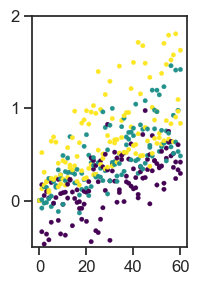

In [96]:
fig, ax = plt.subplots(figsize=(2,3))
sns.scatterplot(x='time',y='val',data=zz[(zz.ele=='APP')&(zz.time.between(0,60))],
                hue='dox',edgecolor=None,s=10,palette='viridis',alpha=1)
# sns.scatterplot(x='time_h',y='FRET_norm_surface',data=df[(df.rep==2)&(df.dox!=2)&(df.ele=='dAPP')],
#                 hue='dox',edgecolor=None,s=10,palette='viridis',alpha=1)

plt.ylim([-.5,2])
plt.locator_params(axis='both',nbins=4)
plt.yticks(fontsize=12)
plt.xticks(fontsize=12)
plt.ylabel('')
plt.xlabel('')
#plt.yscale('log')
plt.legend([],frameon=False)

In [97]:
# def linearReg(x,a):
#     '''fitting recovery 
#      - I_zero: Bottom
#      - a: 
#      - b: beta '''
#     return a*x 
# def fit_curve(x,y):
#     fit, covar = opt.curve_fit(linearReg, x, y,
#                                absolute_sigma = True,maxfev=10000)
#     sigma_ab = np.sqrt(np.diagonal(covar))
#     y_pred = linearReg(x, *fit)
#     print(r2_score(y, y_pred))
#     slope = ufloat(fit[0], sigma_ab[0])
#     #b = ufloat(fit[1], sigma_ab[1])
#     print("Covariance matrix:\n", covar)
#     text_res = "Best fit parameters:\na = {}\nb = {}".format(slope, b)
#     print(sigma_ab)
#     return fit,sigma_ab[0],r2_score(y, y_pred)
# r =[]
# for ele in ['APP','dAPP']:
#     for i in [-1,0,1]:
#         #fit = fit_curve(zz[(zz.ele==ele)&(zz.dox==i)].time,zz[(zz.ele==ele)&(zz.dox==i)].val)
#         fit,sigma_ab,r2 = fit_curve(plot_df[(plot_df.ele==ele)&(plot_df.dox==i)].time,plot_df[(plot_df.ele==ele)&(plot_df.dox==i)].val)
#         r.append({'slope':fit[0],'dox':i,'ele':ele,'error':sigma_ab,'r2':r2})#'b':fit[1]
#     #r.append({'slope':fit_curve(plot_df[(plot_df.ele=='dAPP')&(plot_df.dox==0)].time,plot_df[(plot_df.ele=='dAPP')&(plot_df.dox==i)].val),'dox':i,'ele':'dAPP'})

In [98]:
from scipy.stats import linregress
def fit_curve(x, y):
    res = linregress(x, y,alternative='greater')
    
    slope = ufloat(res.slope, res.stderr)
    intercept = res.intercept
    r2 = res.rvalue ** 2
    
    print(f"R² = {r2:.4f}")
    print(f"Slope = {slope}")
    
    return res.slope, res.stderr, intercept, r2


In [100]:
plot_df

,x,y,y_pred,stds,dox,ele
0,1,0.672535,0.028420,0.364065,-1,APP
1,2,0.617066,0.056545,0.318875,-1,APP
2,3,0.608313,0.084379,0.304352,-1,APP
3,4,0.589820,0.111924,0.296457,-1,APP
4,5,0.607321,0.139184,0.293064,-1,APP
...,...,...,...,...,...,...
3295,546,1.023777,1.158653,0.829883,1,dAPP
3296,547,1.055710,1.160269,0.859953,1,dAPP
3297,548,1.046754,1.161884,0.846645,1,dAPP
3298,549,1.040310,1.163496,0.836488,1,dAPP


In [101]:
r = []
fits = []

for ele in ['APP', 'dAPP']:
    for i in [-1, 0, 1]:
        x_vals = zz[(zz.ele == ele) & (zz.dox == i)&(zz.time.between(0,60))].time
        y_vals = zz[(zz.ele == ele) & (zz.dox == i)&(zz.time.between(0,60))].val
        # x_vals = plot_df[(plot_df.ele == ele) & (plot_df.dox == i)].time
        # y_vals = plot_df[(plot_df.ele == ele) & (plot_df.dox == i)].val        
        slope, sigma_ab, intercept, r2 = fit_curve(x_vals, y_vals)
        print(slope)
        r.append({'slope': slope, 'dox': i, 'ele': ele, 'error': sigma_ab, 'r2': r2,'intercept':intercept})
        fits.append({'x': x_vals, 'y': y_vals, 'slope': slope, 'intercept': intercept, 'ele': ele, 'dox': i})


R² = 0.4063
Slope = 0.0114+/-0.0013
0.011446363697756333
R² = 0.5366
Slope = 0.0145+/-0.0012
0.014471343714999465
R² = 0.4113
Slope = 0.0163+/-0.0018
0.016281384597807747
R² = 0.2492
Slope = 0.0026+/-0.0004
0.0026095235635305693
R² = 0.2657
Slope = 0.0029+/-0.0004
0.002948020404935678
R² = 0.2403
Slope = 0.0028+/-0.0005
0.0028160351220690317


In [102]:
rr = pd.DataFrame(r)
rr.sort_values(by='ele',ascending=False)

,slope,dox,ele,error,r2,intercept
3,0.002610,-1,dAPP,0.000413,0.249215,0.000651
4,0.002948,0,dAPP,0.000447,0.265680,0.005999
5,0.002816,1,dAPP,0.000457,0.240332,-0.012544
0,0.011446,-1,APP,0.001263,0.406268,-0.170366
1,0.014471,0,APP,0.001228,0.536586,0.036116
2,0.016281,1,APP,0.001778,0.411259,0.217688


/var/folders/5x/p2xckt5d54zdnw2nd23zc4lm0000gp/T/ipykernel_4643/3023131226.py:9: UserWarning: 'set_params()' not defined for locator of type <class 'matplotlib.category.StrCategoryLocator'>
  plt.locator_params(axis='both',nbins=4)


([0, 1, 2], [Text(0, 0, '-1'), Text(1, 0, '0'), Text(2, 0, '1')])

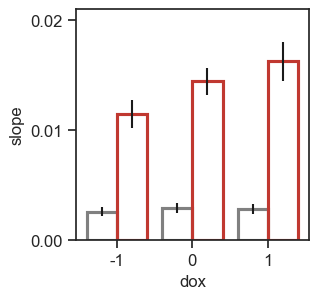

In [103]:

fig, ax = plt.subplots(figsize=(3,3))
# rr = pd.DataFrame(r)
ax  = sns.barplot(fill=0,x='dox',y='slope',data=rr,errorbar=None,hue='ele',palette=['gray','#C03830'],hue_order=['dAPP','APP'])
x_coords = [p.get_x() + 0.5 * p.get_width() for p in ax.patches]
y_coords = [p.get_height() for p in ax.patches]
ax.errorbar(x=x_coords[:6], y=y_coords[:6], yerr=rr.sort_values(by='ele',ascending=False)["error"], fmt="none", c="k")
plt.legend([],frameon=False)
plt.ylim([0,.021])
plt.locator_params(axis='both',nbins=4)
plt.yticks(fontsize=12)
plt.xticks(fontsize=12)
#plt.savefig('TR-FRET_dox_v7.svg',bbox_inches='tight',transparent=True)

In [104]:
plot = []
for dox in [-1,0,1]:
    yy = zz[(zz.ele=='APP')&(zz.dox==dox)&(zz.time.between(0,60))].loc[:,['rep','time','val']].groupby(['time']).mean().reset_index().val.rolling(window=7,min_periods=1,center=True).mean()
    yyy = zz[(zz.ele=='dAPP')&(zz.dox==dox)&(zz.time.between(0,60))].loc[:,['rep','time','val']].groupby(['time']).mean().reset_index().val.rolling(window=7,min_periods=1,center=True).mean()
    for i in enumerate(yy):
        plot.append({'time':i[0],'dox':dox,'val':yy[i[0]],'ele':'APP'})
        plot.append({'time':i[0],'dox':dox,'val':yyy[i[0]],'ele':'dAPP'})

In [105]:
# Figure Used in Figure 7E

,slope,dox,ele,error,r2,intercept
2,0.016281,1,APP,0.001778,0.411259,0.217688


(array([-25.,   0.,  25.,  50.,  75.]),
 [Text(-25.0, 0, '−25'),
  Text(0.0, 0, '0'),
  Text(25.0, 0, '25'),
  Text(50.0, 0, '50'),
  Text(75.0, 0, '75')])

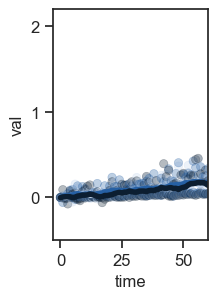

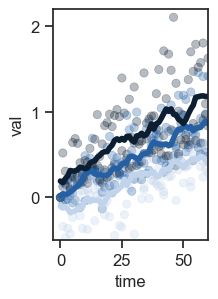

In [107]:
plot_df =pd.DataFrame(plot) 
pal = ['#C2D4EC','#2660A4','#0C1E31']
fig, ax = plt.subplots(figsize=(2,3))
sns.lineplot(x='time',y='val',data=plot_df[plot_df.ele=='dAPP'],hue='dox',hue_order=[-1,0,1],
             palette=pal,lw=4)
sns.scatterplot(x='time',y='val',data=zz[(zz.ele=='dAPP')&(zz.time.between(0,60))],
                hue='dox',edgecolor=None,hue_order=[-1,0,1],
             palette=pal,alpha=.3)
# ax.plot(range(0,60), rr[(rr.ele=='dAPP')&(rr.dox==-1)].intercept.values[0] + rr[(rr.ele=='dAPP')&(rr.dox==-1)].slope.values[0]*range(0,60), 'r', label='fitted line')
# ax.plot(range(0,60), rr[(rr.ele=='dAPP')&(rr.dox==0)].intercept.values[0] + rr[(rr.ele=='dAPP')&(rr.dox==-1)].slope.values[0]*range(0,60), 'r', label='fitted line')
# ax.plot(range(0,60), rr[(rr.ele=='dAPP')&(rr.dox==1)].intercept.values[0] + rr[(rr.ele=='dAPP')&(rr.dox==-1)].slope.values[0]*range(0,60), 'r', label='fitted line')

plt.legend([],frameon=False)
plt.ylim([-.5,2.2]) 
plt.xlim([-3,60])
plt.locator_params(axis='y',nbins=4)
plt.yticks(fontsize=12)
plt.xticks(fontsize=12)
plt.savefig('TR-FRET_dox_dAPP_v7.svg',bbox_inches='tight',transparent=True)
fig, ax = plt.subplots(figsize=(2,3))
sns.lineplot(x='time',y='val',data=plot_df[plot_df.ele=='APP'],hue='dox',hue_order=[-1,0,1],
             palette=pal
             ,lw=4)
#sns.scatterplot(x='time',y='val',data=plot_df[plot_df.ele=='APP'],hue='dox',edgecolor=None,palette='viridis')
sns.scatterplot(x='time',y='val',data=zz[(zz.ele=='APP')&(zz.time.between(0,60))],hue='dox',
                edgecolor=None,hue_order=[-1,0,1],
             palette=pal,alpha=.3)
# ax.plot(range(0,60), rr[(rr.ele=='APP')&(rr.dox==-1)].intercept.values[0] + rr[(rr.ele=='APP')&(rr.dox==-1)].slope.values[0]*range(0,60), 'r', label='fitted line')
# ax.plot(range(0,60), rr[(rr.ele=='APP')&(rr.dox==0)].intercept.values[0] + rr[(rr.ele=='APP')&(rr.dox==-1)].slope.values[0]*range(0,60), 'r', label='fitted line')
# ax.plot(range(0,60), rr[(rr.ele=='APP')&(rr.dox==1)].intercept.values[0] + rr[(rr.ele=='APP')&(rr.dox==-1)].slope.values[0]*range(0,60), 'r', label='fitted line')
plt.legend([],frameon=False)
plt.ylim([-.5,2.2]) 
plt.xlim([-3,60])
plt.locator_params(axis='y',nbins=4)
plt.yticks(fontsize=12)
plt.xticks(fontsize=12)
#plt.savefig('TR-FRET_dox_APP_v7.svg',bbox_inches='tight',transparent=True)


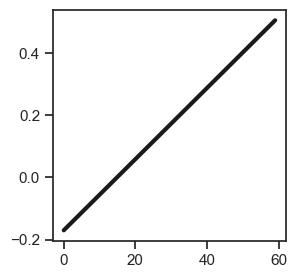

In [108]:
fig, ax = plt.subplots(figsize=(3,3))
ax.plot(range(0,60), rr[(rr.ele=='APP')&(rr.dox==-1)].intercept.values[0] + rr[(rr.ele=='APP')&(rr.dox==-1)].slope.values[0]*range(0,60), 'k-',lw=3)
#plt.savefig('TR-FRET_dox_APP_v8.svg',bbox_inches='tight',transparent=True)


In [109]:
z_cmv = []
for t in set(df_FRET.time):
    t_1 = df_FRET[(df_FRET.ele=='dAPP')&(df_FRET.time==t)].FRET.mean()
    t_0 = df_FRET[(df_FRET.ele=='dAPP')&(df_FRET.time==0)].FRET.mean()
    z_cmv.append({'val':t_1-t_0,'dox':'CMV','rep':j,'ele':'dAPP','time':t})
    t_1 = df_FRET[(df_FRET.ele=='APP')&(df_FRET.time==t)].FRET.mean()
    t_0 = df_FRET[(df_FRET.ele=='APP')&(df_FRET.time==0)].FRET.mean()
    z_cmv.append({'val':t_1-t_0,'ele':'APP','time':t})
    t_1 = df_FRET[(df_FRET.ele=='control')&(df_FRET.time==t)].FRET.mean()
    t_0 = df_FRET[(df_FRET.ele=='control')&(df_FRET.time==0)].FRET.mean()
    z_cmv.append({'val':t_1-t_0,'ele':'control','time':t})
zz_cmv = pd.DataFrame(z_cmv)

In [110]:
zz_cmv[(zz_cmv.ele=='APP')&(zz_cmv.time.between(0,60))].loc[:,['time','val']].groupby(['time']).mean().reset_index().val.rolling(window=7,min_periods=1,center=True).mean()

0     -0.044453
1     -0.050681
2     -0.054349
3     -0.057645
4     -0.060108
         ...   
116    0.978029
117    1.012217
118    1.031010
119    1.048925
120    1.042939
Name: val, Length: 121, dtype: float64

In [111]:
plot_cmv = []
yy = zz_cmv[(zz_cmv.ele=='APP')&(zz_cmv.time.between(0,60))].loc[:,['rep','time','val']].groupby(['time']).mean().reset_index().val.rolling(window=7,min_periods=1,center=True).mean()
yyy = zz_cmv[(zz_cmv.ele=='dAPP')&(zz_cmv.time.between(0,60))].loc[:,['rep','time','val']].groupby(['time']).mean().reset_index().val.rolling(window=7,min_periods=1,center=True).mean()
y4 = zz_cmv[(zz_cmv.ele=='control')&(zz_cmv.time.between(0,60))].loc[:,['rep','time','val']].groupby(['time']).mean().reset_index().val.rolling(window=7,min_periods=1,center=True).mean()
for i in enumerate(yy):
    plot_cmv.append({'time':i[0]/2,'val':yy[i[0]],'ele':'APP'})
    plot_cmv.append({'time':i[0]/2,'val':yyy[i[0]],'ele':'dAPP'})
    plot_cmv.append({'time':i[0]/2,'val':y4[i[0]],'ele':'control'})

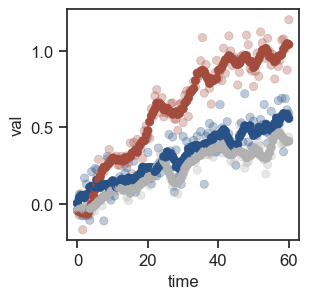

In [112]:
fig, ax = plt.subplots(figsize=(3,3))
sns.scatterplot(x='time',y='val',data=pd.DataFrame(z_cmv),hue='ele',alpha=.3,hue_order=['dAPP','APP','control'],palette=['#B1B1B2','#A34B3D','#285185'],edgecolor=None)
sns.scatterplot(x='time',y='val',data=pd.DataFrame(plot_cmv),hue='ele',hue_order=['dAPP','APP','control'],palette=['#B1B1B2','#A34B3D','#285185'],edgecolor=None)
plt.legend([],frameon=False)
plt.locator_params(axis='y',nbins=4)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.savefig('TR-FRET_dox_CMV_v8.svg',bbox_inches='tight',transparent=True)


In [113]:
df_FRET[(df_FRET.ele=='dAPP')&(df_FRET.time==t)].FRET.mean()

0.6378587699316628

In [114]:
cmv = []
df_cmv = pd.read_excel("/Users/aelazar/Library/CloudStorage/OneDrive-SharedLibraries-St.JudeChildren'sResearchHospital/Trivedi, Vikas - Assaf-Vikas/IDR_dSAMs/TR-FRET/20250430_APP_dAPP_APP2P_5_10ug_1.xlsx",
              sheet_name='Table All Cycles',
              header=10)
df_cmv = df_cmv.iloc[1:62].reset_index(drop=True)
df_488_csv = pd.read_excel("/Users/aelazar/Library/CloudStorage/OneDrive-SharedLibraries-St.JudeChildren'sResearchHospital/Trivedi, Vikas - Assaf-Vikas/IDR_dSAMs/TR-FRET/20250430_APP_dAPP_APP2P_5_10ug_1.xlsx",
              sheet_name='Sheet2',
              header=0)
df_488_csv

,col,name,488_plate,488_flow
0,A01,APP_5ug_1,288,277.5
1,A02,APP_5ug_2,530,277.5
2,A03,APP_5ug_3,204,277.5
3,B01,dAPP_5ug_1,322,697.0
4,B02,dAPP_5ug_2,307,697.0
5,B03,dAPP_5ug_3,482,697.0
6,C01,APP2P_5ug_1,254,489.0
7,C02,APP2P_5ug_2,393,489.0
8,C03,APP2P_5ug_3,343,489.0
9,D01,APP_10ug_1,356,260.0


In [115]:
plate = []
df_488_csv = pd.read_excel("/Users/aelazar/Library/CloudStorage/OneDrive-SharedLibraries-St.JudeChildren'sResearchHospital/Trivedi, Vikas - Assaf-Vikas/IDR_dSAMs/TR-FRET/20250430_APP_dAPP_APP2P_5_10ug_1.xlsx",
              sheet_name='Sheet2',
              header=0)
for i in df_488_csv.index:
    name = df_488_csv.loc[i,'name'].split('_')[0]
    if df_488_csv.loc[i,'name'].split('_')[1][:-2]!='':
        dna = int(df_488_csv.loc[i,'name'].split('_')[1][:-2])
    else:
        dna  = 0
    plate.append({'col':df_488_csv.loc[i,'col'],
                  'ele':name,'DNA':dna,'surface':df_488_csv.loc[i,'488_flow'],'rep':1})
df_cmv = pd.read_excel("/Users/aelazar/Library/CloudStorage/OneDrive-SharedLibraries-St.JudeChildren'sResearchHospital/Trivedi, Vikas - Assaf-Vikas/IDR_dSAMs/TR-FRET/2025_05_02_APP_dAPP_2P_2.5_5_10_3.xlsx",
              sheet_name='Sheet3',
              header=0)
df_cmv = df_cmv.iloc[0:62].reset_index(drop=True)
df_488_csv = pd.read_excel("/Users/aelazar/Library/CloudStorage/OneDrive-SharedLibraries-St.JudeChildren'sResearchHospital/Trivedi, Vikas - Assaf-Vikas/IDR_dSAMs/TR-FRET/2025_05_02_APP_dAPP_2P_2.5_5_10_3.xlsx",
              sheet_name='Sheet2',
              header=None)
for i in df_488_csv.loc[1:,:].index:
    for j in [1,2,3]:
        name = df_488_csv.loc[i,4]
        DNA = df_488_csv.loc[i,5]
        if df_488_csv.loc[i,4]=='C':
            name ='Ctrl'
            DNA = 0
        plate.append({'col':df_488_csv.loc[i,j],
                  'ele':name,'DNA':DNA,'surface':df_488_csv.loc[i,6],'rep':2})
df_488_csv = pd.read_excel("/Users/aelazar/Library/CloudStorage/OneDrive-SharedLibraries-St.JudeChildren'sResearchHospital/Trivedi, Vikas - Assaf-Vikas/IDR_dSAMs/TR-FRET/2025_05_02_APP_dAPP_2P_2.5_5_10_4.xlsx",
              sheet_name='Sheet2',
              header=None)
for i in df_488_csv.loc[:,:].index:
    for j in [0,1,2]:
        name = df_488_csv.loc[i,3]
        DNA = df_488_csv.loc[i,4]
        if df_488_csv.loc[i,3]=='C':
            name ='Ctrl'
            DNA = 0
        plate.append({'col':df_488_csv.loc[i,j],
                  'ele':name,'DNA':DNA,'surface':df_488_csv.loc[i,5],'rep':3})
df_plate = pd.DataFrame(plate)

In [116]:
df_plate

,col,ele,DNA,surface,rep
0,A01,APP,5.0,277.5,1
1,A02,APP,5.0,277.5,1
2,A03,APP,5.0,277.5,1
3,B01,dAPP,5.0,697.0,1
4,B02,dAPP,5.0,697.0,1
...,...,...,...,...,...
76,B09,APP2P,10.0,304.0,3
77,C09,APP2P,10.0,304.0,3
78,A10,Ctrl,0.0,132.0,3
79,B10,Ctrl,0.0,132.0,3


In [117]:
df_cmv = pd.read_excel("/Users/aelazar/Library/CloudStorage/OneDrive-SharedLibraries-St.JudeChildren'sResearchHospital/Trivedi, Vikas - Assaf-Vikas/IDR_dSAMs/TR-FRET/20250430_APP_dAPP_APP2P_5_10ug_1.xlsx",
              sheet_name='Table All Cycles',
              header=10)
cmv = []
time = 0
for ind in df_cmv.iloc[1:61].index:
    for col in set(df_plate[df_plate.rep==1].col):
        val = df_cmv.loc[ind,col]
        ele = df_plate[(df_plate.col==col)&(df_plate.rep==1)].ele.values[0]
        DNA = df_plate[(df_plate.col==col)&(df_plate.rep==1)].DNA.values[0]
        surface = df_plate[(df_plate.col==col)&(df_plate.rep==1)].surface.values[0]
        cmv.append({'ele':ele,'DNA':DNA,'FRET':val/surface,'time':time,'rep':1})
    time = time +1
df_cmv = pd.read_excel("/Users/aelazar/Library/CloudStorage/OneDrive-SharedLibraries-St.JudeChildren'sResearchHospital/Trivedi, Vikas - Assaf-Vikas/IDR_dSAMs/TR-FRET/2025_05_02_APP_dAPP_2P_2.5_5_10_3.xlsx",
              sheet_name='Sheet3',
              header=0)
time = 0
for ind in df_cmv.iloc[1:61].index:
    for col in set(df_plate[df_plate.rep==2].col):
        val = df_cmv.loc[ind,col]
        ele = df_plate[(df_plate.col==col)&(df_plate.rep==2)].ele.values[0]
        DNA = df_plate[(df_plate.col==col)&(df_plate.rep==2)].DNA.values[0]
        surface = df_plate[(df_plate.col==col)&(df_plate.rep==2)].surface.values[0]
        cmv.append({'ele':ele,'DNA':DNA,'FRET':val/surface,'time':time,'rep':2})
    time = time +1
df_cmv = pd.read_excel("/Users/aelazar/Library/CloudStorage/OneDrive-SharedLibraries-St.JudeChildren'sResearchHospital/Trivedi, Vikas - Assaf-Vikas/IDR_dSAMs/TR-FRET/2025_05_02_APP_dAPP_2P_2.5_5_10_4.xlsx",
              sheet_name='Sheet1',
              header=0)
time = 0
for ind in df_cmv.iloc[1:61].index:
    for col in set(df_plate[df_plate.rep==3].col):
        val = df_cmv.loc[ind,col]
        ele = df_plate[(df_plate.col==col)&(df_plate.rep==3)].ele.values[0]
        DNA = df_plate[(df_plate.col==col)&(df_plate.rep==3)].DNA.values[0]
        surface = df_plate[(df_plate.col==col)&(df_plate.rep==3)].surface.values[0]
        cmv.append({'ele':ele,'DNA':DNA,'FRET':val/surface,'time':time,'rep':3})
    time = time +1

In [118]:
df_cmv = pd.DataFrame(cmv)

In [119]:
df_cmv = df_cmv.groupby(['time','rep','DNA','ele']).mean().reset_index()

In [120]:
for ele in ['APP','dAPP','APP2P']:
    for DNA in [5,10]:
        reff = df_cmv[(df_cmv.rep==1)&(df_cmv.time==10)&(df_cmv.DNA==DNA)&(df_cmv.ele==ele)].FRET.values[0]
        for j in df_cmv[(df_cmv.rep==1)&(df_cmv.DNA==DNA)&(df_cmv.ele==ele)].index:
            df_cmv.loc[j,'norm_FRET'] = df_cmv.loc[j,'FRET'] - reff
for rep in [2,3]:
    for ele in ['APP','dAPP','APP2P']:
            for DNA in [2.5,5,10]:
                reff = df_cmv[(df_cmv.rep==rep)&(df_cmv.time==10)&(df_cmv.DNA==DNA)&(df_cmv.ele==ele)].FRET.values[0]
                for j in df_cmv[(df_cmv.rep==rep)&(df_cmv.DNA==DNA)&(df_cmv.ele==ele)].index:
                    df_cmv.loc[j,'norm_FRET'] = df_cmv.loc[j,'FRET'] - reff
for rep in [1,2,3]:
    for ele in ['Ctrl']:
            for DNA in [0]:
                reff = df_cmv[(df_cmv.rep==rep)&(df_cmv.time==10)&(df_cmv.DNA==DNA)&(df_cmv.ele==ele)].FRET.values[0]
                for j in df_cmv[(df_cmv.rep==rep)&(df_cmv.DNA==DNA)&(df_cmv.ele==ele)].index:
                    df_cmv.loc[j,'norm_FRET'] = df_cmv.loc[j,'FRET'] - reff

In [121]:
df_cmv['time_new'] = df_cmv['time'] - 10

In [122]:
df_cmv.drop_duplicates(subset=['FRET'])

,time,rep,DNA,ele,FRET,norm_FRET,time_new
0,0,1,0.0,Ctrl,56.473850,-17.771165,-10
1,0,1,5.0,APP,48.015180,-10.811477,-10
2,0,1,5.0,APP2P,24.507780,-7.619916,-10
3,0,1,5.0,dAPP,18.205871,-4.302614,-10
4,0,1,10.0,APP,53.611011,-12.124247,-10
...,...,...,...,...,...,...,...
1615,59,3,5.0,APP2P,155.181109,20.234955,49
1616,59,3,5.0,dAPP,155.275428,16.957319,49
1617,59,3,10.0,APP,385.957930,26.766068,49
1618,59,3,10.0,APP2P,181.848030,20.261543,49


In [123]:
df_cmv[(df_cmv.DNA==5)]

,time,rep,DNA,ele,FRET,norm_FRET,time_new
1,0,1,5.0,APP,48.015180,-10.811477,-10
2,0,1,5.0,APP2P,24.507780,-7.619916,-10
3,0,1,5.0,dAPP,18.205871,-4.302614,-10
11,0,2,5.0,APP,365.299175,-15.168072,-10
12,0,2,5.0,APP2P,132.457358,6.472832,-10
...,...,...,...,...,...,...,...
1605,59,2,5.0,APP2P,161.117022,35.132496,49
1606,59,2,5.0,dAPP,176.437666,25.204806,49
1614,59,3,5.0,APP,383.274655,27.318657,49
1615,59,3,5.0,APP2P,155.181109,20.234955,49


In [124]:
smooth = []
for DNA in [2.5,5,10]:
    for ele in ['APP','dAPP','APP2P']:
        temp = df_cmv[(df_cmv.DNA==DNA)&(df_cmv.time_new.between(0,50))&(df_cmv.ele==ele)].loc[:,['time_new','norm_FRET']].groupby(['time_new']).mean()
        c = 0
        for i in temp.rolling(window=7,center=True,min_periods=1).mean().values:
            smooth.append({'time':c,'FRET':i[0],'ele':ele,'DNA':DNA})
            c = c+1
for ele in ['Ctrl']:
    temp = df_cmv[(df_cmv.DNA==0)&(df_cmv.time_new.between(0,50))&(df_cmv.rep.isin([1,2]))].loc[:,['time_new','norm_FRET']].groupby(['time_new']).mean()
    c = 0
    for i in temp.rolling(window=7,center=True,min_periods=1).mean().values:
        smooth.append({'time':c,'FRET':i[0],'ele':ele,'DNA':0})
        c = c+1

In [125]:
smooth_df = pd.DataFrame(smooth)

In [127]:
# Fiugre used in S7

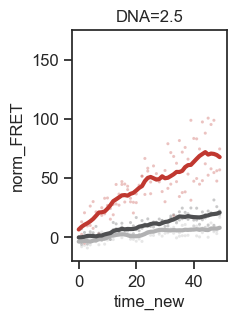

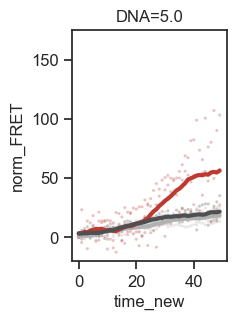

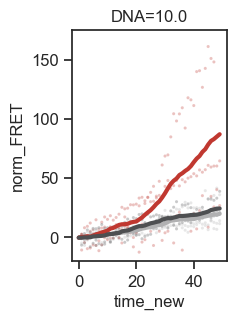

In [126]:
for dna in [2.5,5,10]:
    fig, ax = plt.subplots(figsize=(2,3))
    sns.scatterplot(x='time_new',y='norm_FRET',data=df_cmv[(df_cmv.DNA==dna)&(df_cmv.time_new.between(0,50))],
                    hue='ele',alpha=.3,s=5,hue_order=['dAPP','APP','APP2P'],palette=['#B1B1B2','#C03830','#4E4F51'])
    sns.lineplot(x='time',y='FRET',data=smooth_df[smooth_df.DNA==dna],hue='ele',lw=3,
                hue_order=['dAPP','APP','APP2P'],palette=['#B1B1B2','#C03830','#4E4F51'])
    plt.ylim([-20,175])
    plt.legend([],frameon=False)
    plt.locator_params(axis='both',nbins=4)
    plt.xticks(fontsize=12)
    plt.yticks(fontsize=12)
    plt.title('DNA=%.1f'%dna)
    plt.savefig('TR-FRET_dox_CMV_%d.svg'%dna,bbox_inches='tight',transparent=True)

